In [39]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/code-forge-club-ml-challenge-fraud-detection-ai-ds/credit_card_fraud_sample_submission.csv
/kaggle/input/competitions/code-forge-club-ml-challenge-fraud-detection-ai-ds/credit_card_fraud_test.csv
/kaggle/input/competitions/code-forge-club-ml-challenge-fraud-detection-ai-ds/credit_card_fraud_train.csv


In [40]:
#import libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline


#Load Data 
train = pd.read_csv("/kaggle/input/competitions/code-forge-club-ml-challenge-fraud-detection-ai-ds/credit_card_fraud_train.csv")
test = pd.read_csv("/kaggle/input/competitions/code-forge-club-ml-challenge-fraud-detection-ai-ds/credit_card_fraud_test.csv")

print("Training Shape:", train.shape)
print("Testing Shape:", test.shape)

train.head()


Training Shape: (120, 10)
Testing Shape: (30, 9)


,TransactionID,TransactionAmount,TransactionType,TransactionHour,MerchantCategory,CustomerAge,AccountAgeMonths,LocationMismatch,DeviceType,Fraud
0,100001,220.83,Online,13,Grocery,33,102,0,Mobile,0
1,100002,132.87,POS,15,Food,40,86,0,Tablet,0
2,100003,249.17,Online,13,Food,28,15,0,Mobile,0
3,100004,501.91,POS,11,Retail,29,67,0,Mobile,1
4,100005,123.06,POS,18,Retail,27,76,0,Tablet,0


In [41]:
#Basic information about data

train.info()
train.describe()
train.isnull().sum()
test.isnull().sum()
print("Duplicate rows:", train.duplicated().sum())
print(train["Fraud"].value_counts())
print(train["Fraud"].value_counts(normalize=True) * 100)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   TransactionID      120 non-null    int64  
 1   TransactionAmount  120 non-null    float64
 2   TransactionType    120 non-null    object 
 3   TransactionHour    120 non-null    int64  
 4   MerchantCategory   120 non-null    object 
 5   CustomerAge        120 non-null    int64  
 6   AccountAgeMonths   120 non-null    int64  
 7   LocationMismatch   120 non-null    int64  
 8   DeviceType         120 non-null    object 
 9   Fraud              120 non-null    int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 9.5+ KB
Duplicate rows: 0
Fraud
0    96
1    24
Name: count, dtype: int64
Fraud
0    80.0
1    20.0
Name: proportion, dtype: float64


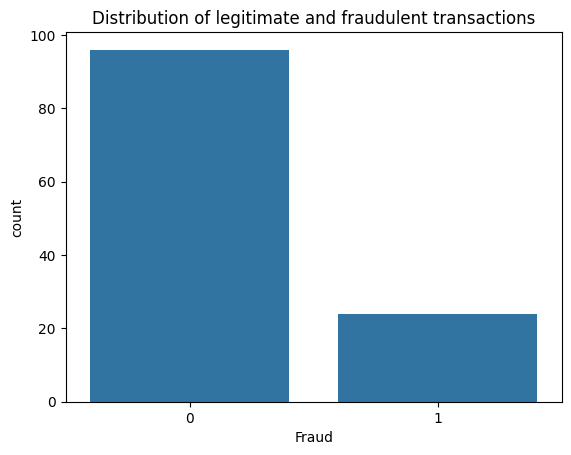

In [42]:
#Exploratory Data Analysis

#fraud distribution 
sns.countplot(data=train, x="Fraud")
plt.title("Distribution of legitimate and fraudulent transactions")
plt.show()

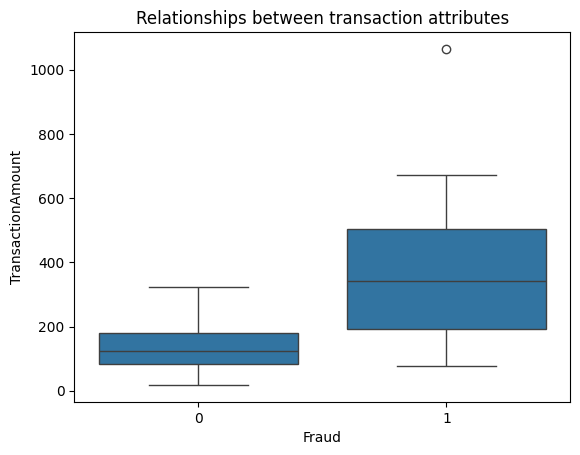

In [43]:
#Relationships between transaction attributes.

sns.boxplot(data=train, x="Fraud", y="TransactionAmount")
plt.title("Relationships between transaction attributes")
plt.show()

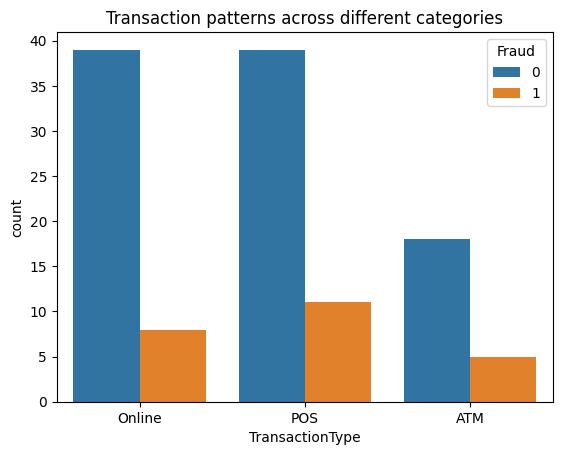

In [44]:
#Transaction patterns across different categories.

sns.countplot(data=train, x="TransactionType", hue="Fraud")
plt.title("Transaction patterns across different categories")
plt.show()

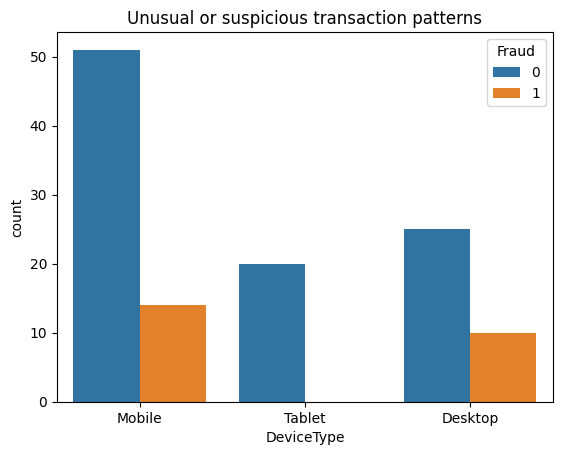

In [45]:
#Unusual or suspicious transaction patterns.

sns.countplot(data=train, x="DeviceType", hue="Fraud")
plt.title("Unusual or suspicious transaction patterns")
plt.show()

In [46]:
# missing value 
print("Missing values in training data:")
print(train.isnull().sum())
print("\nMissing values in test data:")
print(test.isnull().sum())

train = train.dropna(thresh=len(train) * 0.7, axis=1) 
test = test.dropna(thresh=len(test) * 0.7, axis=1)

for col in train.select_dtypes(include=np.number).columns:
    if train[col].isnull().any():
        median_val = train[col].median()          
        train[col] = train[col].fillna(median_val)
        test[col] = test[col].fillna(median_val)

for col in train.select_dtypes(include="object").columns:
    if train[col].isnull().any():
        mode_val = train[col].mode()[0]
        train[col] = train[col].fillna(mode_val)
        test[col] = test[col].fillna(mode_val)

Missing values in training data:
TransactionID        0
TransactionAmount    0
TransactionType      0
TransactionHour      0
MerchantCategory     0
CustomerAge          0
AccountAgeMonths     0
LocationMismatch     0
DeviceType           0
Fraud                0
dtype: int64

Missing values in test data:
TransactionID        0
TransactionAmount    0
TransactionType      0
TransactionHour      0
MerchantCategory     0
CustomerAge          0
AccountAgeMonths     0
LocationMismatch     0
DeviceType           0
dtype: int64


In [47]:
# Removing or investigating duplicate records.
print("Duplicates in training data:", train.duplicated().sum())
train = train.drop_duplicates()


Duplicates in training data: 0
